# 5 · A hint from the host

Notebook 4 found what holds the client back: from N-2 and N it cannot tell whether a scroll
goes on, and one motion per tile cannot follow a window dragged over a still desktop. The
host can. It captures at the display rate and sends every second frame - so it *has* N+1,
the frame the client makes, and drops it. Before it does, it can measure how each client
tile moved from N to N+1 and send that: two numbers a tile.

**How each works, and whether it learns:**

| | the motion | measured from | learns? |
| --- | --- | --- | --- |
| repeat | none | - | no |
| tile search (published) | half the motion between N-2 and N, one per tile | the two received frames, on the client | no |
| **hint** | the motion from N to N+1, one per tile | the clean frames N and N+1, on the host | no: a search too, run where the answer is |
| hint per block | the same, one per 32 px block | the same | no |
| hinted graph | the hint where it arrived in time, the search where not | both | no |

Steps:

1. **Data** - notebook 4's whole frames in the client's tiles, with the clean frames N and
   N+1 the host captured.
2. **The hint** - measured exhaustively and as cheaply as a host can afford; how precise it
   has to be.
3. **What it is worth** - against repeat and the search, per tile and per block, by kind.
4. **Bits** - what it costs the stream.
5. **Late hints** - when one arrives after its frame is due, the tile falls back to the search.
6. **Stop or go**, frame by frame, and what it looks like.
7. **Export** - one graph that takes the hint and falls back by itself.

**Not feasible for desktop-streamer as it is.** The hint needs the host to capture at twice
the stream's rate, and a real host captures at the rate it streams - there is no frame between
to measure. A prototype in desktop-streamer was reverted for that reason; this notebook stays
as the measurement of what the frame the client cannot see would be worth, and its graph goes
to `checkpoints/export/`, not to `dist/`.

Nothing is trained. Needs: `00_data_preprocess.ipynb` and the sources it read.
Results: `summary.md`, "A hint from the host".

In [1]:
"""Settings."""

import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import clips, hints, metrics, models, runs, show, training, webexport
from helpers.training import DEVICE

RADIUS, SCALE, SHARPNESS, STRIDE, STILL = 4, 2, 10.0, 2, 0.1   # notebook 3's published search
EVERY = 2                # every 2nd received frame N of a clip, as notebook 4
BLOCK = 32               # the per-block hint, in stream pixels
HOST = {"start": 3, "radius": 4, "stop": 0, "sample": 2}         # the host's search: from 1/8 of the source down
LATE = (0.0, 0.1, 0.25, 0.5, 1.0)                                # shares of hints that arrive too late
BATCH_SIZE = 32
SEED = 0
training.seed_everything(SEED)

## 1. Data

The validation clips rebuilt and cut as the client cuts them (`clips.load`), as in notebook
4 - and with `raw`, under every tile the luma of the clean frames N and N+1 at the source's
resolution: what the host captured before the stream shrank and encoded it. The stream is
half that size, so a source pixel is half a stream pixel.

In [2]:
manifest = training.load_manifest()
training.describe(manifest)
STEP = runs.received_every(manifest)
FRACTION = 1 / STEP
scale = manifest["scale"]

started = time.time()
tiles = clips.load(manifest, "val", every=EVERY, raw=True)
masks = clips.groups(manifest, "val", tiles)
KINDS = ["page", "desktop", "photo", "video", "pointer"]
for kind in KINDS:
    masks[f"{kind}, changed"] = masks[kind] & masks["changed"]
frames = (tiles["inputs"], tiles["targets"], masks, tiles["boxes"])
print(f"{len(tiles['inputs'])} tiles, {masks['changed'].sum()} changed, clean luma {tiles['raw'].shape[2:]} under "
      f"each, in {time.time() - started:.0f}s; " + ", ".join(f"{kind} {masks[f'{kind}, changed'].sum()}" for kind in KINDS))

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N-2 and N, the target N+1 (2x frame generation)


6700 tiles, 2488 changed, clean luma (376, 656) under each, in 69s; page 1140, desktop 264, photo 849, video 235, pointer 436


## 2. The hint

`hints.measure` finds, for every tile, the whole-pixel offset that best carries clean N onto
clean N+1 - the mean luma difference over the tile, as notebook 1's shift, but between the
frame the client has and the one it has to make. Three ways:

- **exhaustive, whole stream pixels**: every offset within ±16 stream pixels at the stream's
  resolution - 1,089 of them;
- **exhaustive, half pixels**: the same, then ±1 at the source's resolution: half a stream
  pixel, which is where a scroll by whole window pixels lands after the stream's ×2 shrink;
- **the host's**: every offset within ±4 at an eighth of the source (±32 source pixels,
  the same reach), then ±1 at each finer level, scoring every second pixel - 108 offsets on
  ever larger pictures instead of 1,089 on one.

In [3]:
VARIANTS = {"exhaustive, whole px": {"start": 1, "radius": 16, "stop": 1},
            "exhaustive, half px": {"start": 1, "radius": 16, "stop": 0},
            "host (pyramid), half px": HOST}
measured = {name: [] for name in VARIANTS}
seconds = dict.fromkeys(VARIANTS, 0.0)
with torch.no_grad():
    for first in range(0, len(tiles["raw"]), BATCH_SIZE):
        luma = torch.from_numpy(tiles["raw"][first:first + BATCH_SIZE]).to(DEVICE).float().div_(255)
        before, after = hints.pyramid(luma[:, :1], 3), hints.pyramid(luma[:, 1:], 3)
        for name, settings in VARIANTS.items():
            started = time.time()
            measured[name].append(hints.measure(before, after, **settings).cpu() / scale)
            seconds[name] += time.time() - started
measured = {name: torch.cat(found).numpy() for name, found in measured.items()}   # (S, 2) stream pixels

reference = measured["exhaustive, half px"]
changed = masks["changed"]
for name, found in measured.items():
    same = (np.abs(found - reference).max(1) <= 0.25)
    print(f"{name:26} same as the exhaustive half-pixel search on {same[changed].mean():6.1%} of the changed tiles, "
          f"{seconds[name]:5.1f}s on the GPU for all {len(found)}")
reach = np.abs(reference[changed]).max(1)
print(f"\nchanged tiles moving from N to N+1: none {np.mean(reach == 0):.0%}, up to 4 px {np.mean(reach <= 4):.0%}, "
      f"up to 8 px {np.mean(reach <= 8):.0%}, over 15 px {np.mean(reach > 15):.1%}")

# what the host's search costs a tile: absolute differences, coarse level and the refinements
height, width = tiles["raw"].shape[2:]
work = (2 * HOST["radius"] + 1) ** 2 * (height // 8 - 2 * HOST["radius"]) * (width // 8 - 2 * HOST["radius"])
for level in range(HOST["start"] - 1, HOST["stop"] - 1, -1):
    margin = (HOST["radius"] + 1) * 2 ** (HOST["start"] - level)
    work += 9 * ((height >> level) - 2 * margin) * ((width >> level) - 2 * margin) // HOST["sample"] ** 2
print(f"the host's search: {work / 1e6:.2f} million absolute differences a tile, "
      f"{work * 36 * 30 / 1e9:.1f} billion a second for a 1080p stream's 36 tiles at 30 hints a second")

exhaustive, whole px       same as the exhaustive half-pixel search on  60.7% of the changed tiles,  16.2s on the GPU for all 6700
exhaustive, half px        same as the exhaustive half-pixel search on 100.0% of the changed tiles,  16.6s on the GPU for all 6700
host (pyramid), half px    same as the exhaustive half-pixel search on  94.2% of the changed tiles,   0.5s on the GPU for all 6700

changed tiles moving from N to N+1: none 27%, up to 4 px 84%, up to 8 px 94%, over 15 px 1.3%
the host's search: 0.74 million absolute differences a tile, 0.8 billion a second for a 1080p stream's 36 tiles at 30 hints a second


## 3. What it is worth

`models.Hinted` moves N by the hint - here always in time - with notebook 3's published
search beside it for when it is not. The hint per block is notebook 1's exact shift per 32
px block, between clean N and N+1 at the stream's resolution: where a tile holds two motions.

In [4]:
search = models.TileSearch(RADIUS, SCALE, SHARPNESS, STRIDE, FRACTION, still=STILL).to(DEVICE).eval()
hinted = models.Hinted(search).to(DEVICE).eval()
published = models.Motion(search=search, learned=False)
in_time = {name: np.concatenate([found, np.ones((len(found), 1), np.float32)], 1) for name, found in measured.items()}


class BlockHint(torch.nn.Module):
    """N moved by the motion of each 32 px block from clean N to clean N+1 (`side`: their luma
    at the stream's resolution) - a hint per block."""

    def __init__(self, block, radius=16):
        super().__init__()
        self.shift = models.Shift(radius=radius, block=block, fraction=1.0)

    def forward(self, previous, current, side):
        before, after = (side[:, i:i + 1].expand(-1, 3, -1, -1) for i in (0, 1))
        return models.warp(current, self.shift.field(before, after))


# the clean frames' luma at the stream's resolution, for the per-block hint
stream_luma = np.concatenate([torch.nn.functional.avg_pool2d(torch.from_numpy(tiles["raw"][first:first + 256]).float(),
                                                             scale).div_(255).numpy()
                              for first in range(0, len(tiles["raw"]), 256)])

results = {"repeat": clips.evaluate(models.Repeat(), *frames),
           "tile search (published)": clips.evaluate(published, *frames)}
for name, hint in in_time.items():
    results[f"hint, {name}"] = clips.evaluate(hinted, *frames, side=hint)
results[f"hint per {BLOCK} px block, whole px"] = clips.evaluate(BlockHint(BLOCK), *frames, batch_size=16, side=stream_luma)

for group in ("changed", "all"):
    base = results["tile search (published)"][group]["wpsnr"]
    print(f"\n{group}: {masks[group].sum()} tiles")
    metrics.print_table({name: scores[group] for name, scores in results.items()},
                        extra=lambda name, s, g=group: f"   {s['wpsnr'] - results['repeat'][g]['wpsnr']:+6.2f} dB vs repeat, "
                                                       f"{s['wpsnr'] - results['tile search (published)'][g]['wpsnr']:+6.2f} vs the search")

print(f"\n{'wPSNR (dB), changed':<40}" + "".join(f"{kind:>10}" for kind in KINDS))
for name, scores in results.items():
    print(f"{name:<40}" + "".join(f"{scores[f'{kind}, changed']['wpsnr']:10.2f}" for kind in KINDS))


changed: 2488 tiles
                                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
repeat                              27.15    25.95    57.30    58.64     25.76   0.7676    +0.00 dB vs repeat,  -5.70 vs the search
tile search (published)             32.85    31.76    59.93    61.05     31.22   0.8706    +5.70 dB vs repeat,  +0.00 vs the search
hint, exhaustive, whole px          37.32    36.36    61.72    62.78     35.52   0.9387   +10.18 dB vs repeat,  +4.47 vs the search
hint, exhaustive, half px           38.88    37.93    62.40    63.44     37.05   0.9540   +11.74 dB vs repeat,  +6.03 vs the search
hint, host (pyramid), half px       38.80    37.83    62.33    63.36     36.97   0.9541   +11.65 dB vs repeat,  +5.95 vs the search
hint per 32 px block, whole px      37.78    36.77    62.33    63.40     36.00   0.9515   +10.63 dB vs repeat,  +4.93 vs the search

all: 6700 tiles
                                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   s

## 4. Bits

A tile's hint is (x, y) in half stream pixels, one signed byte each: ±63 stream pixels,
beyond any motion here. Whether it arrived is the client's to know, not the host's to send.
A hint per block costs a bit per block saying whether it moves with its tile, and two bytes
for each that does not.

In [5]:
FPS = 30   # hints a second: one for every frame the client makes
tiles_per_frame = {"640x360 (here)": 4, "1280x720": 16, "1920x1080": 36}
tile_bits = 16
print(f"{'a hint per tile':<26}" + "".join(f"{size}: {n * tile_bits * FPS / 1000:5.1f} kbit/s   "
                                          for size, n in tiles_per_frame.items()))

finder = models.Shift(radius=16, block=BLOCK, fraction=1.0).to(DEVICE)
whole_tile = models.Shift(radius=16, block=None, fraction=1.0).to(DEVICE)
blocks_per_tile, differ = 0, []
with torch.no_grad():
    for first in range(0, len(stream_luma), BATCH_SIZE):
        side = torch.from_numpy(stream_luma[first:first + BATCH_SIZE]).to(DEVICE)
        before, after = (side[:, i:i + 1].expand(-1, 3, -1, -1) for i in (0, 1))
        per_block = finder.offsets_of(before, after)                       # (N, rows, cols) offset index
        per_tile = whole_tile.offsets_of(before, after)                    # (N, 1, 1)
        blocks_per_tile = per_block[0].numel()
        differ.append((per_block != per_tile).flatten(1).sum(1).cpu().numpy())
differ = np.concatenate(differ)
block_bits = tile_bits + blocks_per_tile + 16 * differ
print(f"{'a hint per 32 px block':<26}" + "".join(f"{size}: {n * block_bits.mean() * FPS / 1000:5.1f} kbit/s   "
                                                 for size, n in tiles_per_frame.items()))
print(f"\n{blocks_per_tile} blocks a tile; {differ.mean():.1f} move apart from their tile on average "
      f"({differ[changed].mean():.1f} on the changed tiles). The stream itself: "
      f"{manifest['degradation'].split('at ')[1].split(' bits')[0]} bits a pixel, "
      f"{0.2 * 640 * 360 * FPS / 1e3:.0f}-{1.0 * 640 * 360 * FPS / 1e3:.0f} kbit/s at 640x360")

a hint per tile           640x360 (here):   1.9 kbit/s   1280x720:   7.7 kbit/s   1920x1080:  17.3 kbit/s   


a hint per 32 px block    640x360 (here):  19.3 kbit/s   1280x720:  77.2 kbit/s   1920x1080: 173.7 kbit/s   

50 blocks a tile; 5.9 move apart from their tile on average (15.8 on the changed tiles). The stream itself: 0.2-1.0 bits a pixel, 1382-6912 kbit/s at 640x360


## 5. Late hints

A hint for N+1 is ready one display interval after N was captured, and it needs no encoding
- while N needs its encode and decode first. It should usually be there before N+1 is due,
half an interval after N is shown; when it is not, its tile falls back to the search. One
graph does both: the hint's third number says whether it came (`models.Hinted`). Here a
share of the hints is dropped at random.

In [6]:
rng = np.random.default_rng(SEED)
host_hint = in_time["host (pyramid), half px"]
print(f"{'hints too late':<16}{'wPSNR changed':>15}{'all':>9}")
for late in LATE:
    hint = host_hint.copy()
    hint[:, 2] = rng.random(len(hint)) >= late
    scores = clips.evaluate(hinted, *frames, side=hint)
    print(f"{late:<16.0%}{scores['changed']['wpsnr']:15.2f}{scores['all']['wpsnr']:9.2f}")

hints too late    wPSNR changed      all


0%                        38.80    67.27


10%                       38.10    66.94


25%                       37.52    66.69


50%                       35.59    65.81


100%                      32.85    64.54


## 6. Stop or go, frame by frame

Notebook 4's wheel-scrolled page, every generated frame of it: the search wins while the
scroll runs and falls under repeat on the frame a notch stops. The hint knows when it stops.
Frames where nothing moved are near perfect and capped at 60 dB.

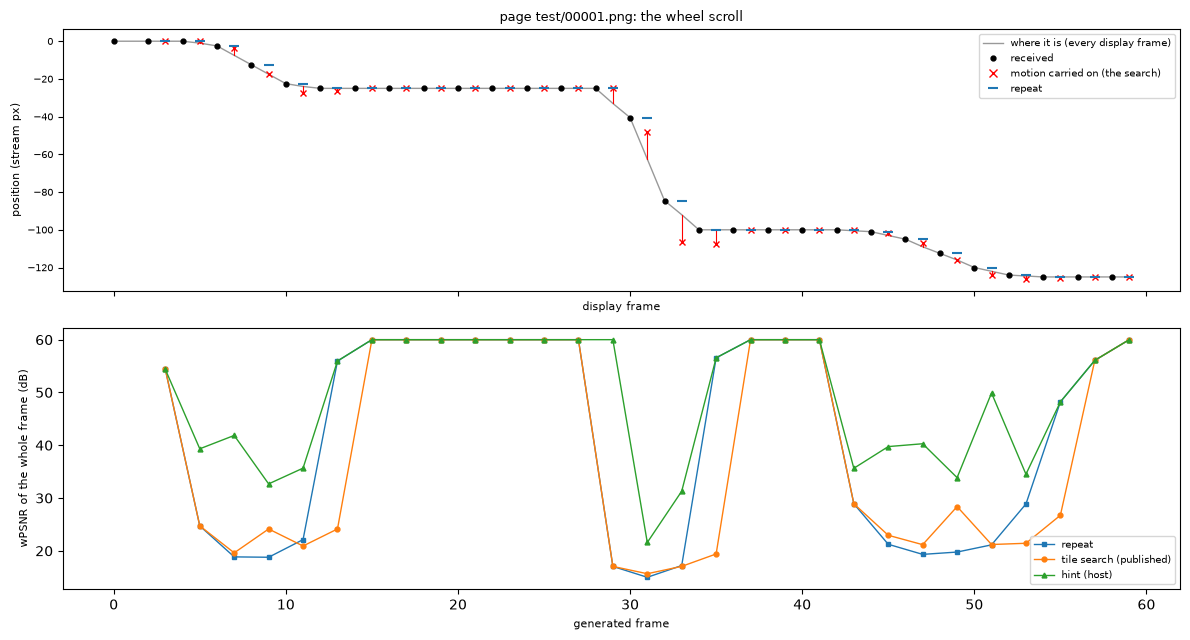

mean over the clip's generated frames (capped at 60): repeat 41.5 dB, tile search (published) 38.8 dB, hint (host) 49.2 dB


In [7]:
source = next(s for s in manifest["splits"]["val"]["sources"] if (s.get("scene") or {}).get("background") == "wheel")
clean, stream = clips.rebuild(source, manifest, raw=True)
clean = torch.from_numpy(clean).float().div_(255) @ metrics.RGB_TO_YUV[0]          # (T, H, W) luma
height, width = stream.shape[1:3]
layout, size = clips.plan(width, height)


def whole(made):
    """A frame put together from its tiles, each giving the region the client keeps."""
    frame = torch.zeros(3, height, width, device=DEVICE)
    for tile, (ix, iy, ox, oy, w, h) in zip(made, layout):
        frame[:, iy + oy:iy + oy + h, ix + ox:ix + ox + w] = tile[:, oy:oy + h, ox:ox + w]
    return frame[None]


made_frames, scores = [], {"repeat": [], "tile search (published)": [], "hint (host)": []}
with torch.no_grad():
    for n in range(STEP, len(stream) - 1, STEP):
        windows = np.stack([stream[[n - STEP, n, n + 1], iy:iy + size[0], ix:ix + size[1]] for ix, iy, *_ in layout])
        previous, current, target = training.to_tensor(windows).unbind(1)
        luma = torch.stack([clean[[n, n + 1], scale * iy:scale * (iy + size[0]), scale * ix:scale * (ix + size[1])]
                            for ix, iy, *_ in layout]).to(DEVICE)
        found = hints.measure(hints.pyramid(luma[:, :1], 3), hints.pyramid(luma[:, 1:], 3), **HOST) / scale
        hint = torch.cat([found, torch.ones(len(found), 1, device=DEVICE)], 1)
        made = {"repeat": current, "tile search (published)": published(previous, current),
                "hint (host)": hinted(previous, current, hint)}
        for name, picture in made.items():
            scores[name].append(min(60.0, metrics.wpsnr(whole(picture), whole(target))))
        made_frames.append(n + 1)

scroll = np.array(source["scene"]["scroll"]) / scale
axis = int(np.abs(scroll[-1] - scroll[0]).argmax())
fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
show.track(top, scroll[:, axis], STEP, FRACTION, f"{source['kind']} {source['file']}: the wheel scroll")
top.legend(fontsize=7)
for (name, values), style in zip(scores.items(), ("s-", "o-", "^-")):
    bottom.plot(made_frames, values, style, ms=3.5, lw=1, label=name)
bottom.set_ylabel("wPSNR of the whole frame (dB)", fontsize=8)
bottom.set_xlabel("generated frame", fontsize=8)
bottom.legend(fontsize=7)
fig.tight_layout()
plt.show()
print("mean over the clip's generated frames (capped at 60): " +
      ", ".join(f"{name} {np.mean(values):.1f} dB" for name, values in scores.items()))

### What it looks like

Changed tiles where the hint gains most over the search: the motion each carries to N+1
(yellow, four times its length), what had to change, and each one's error.

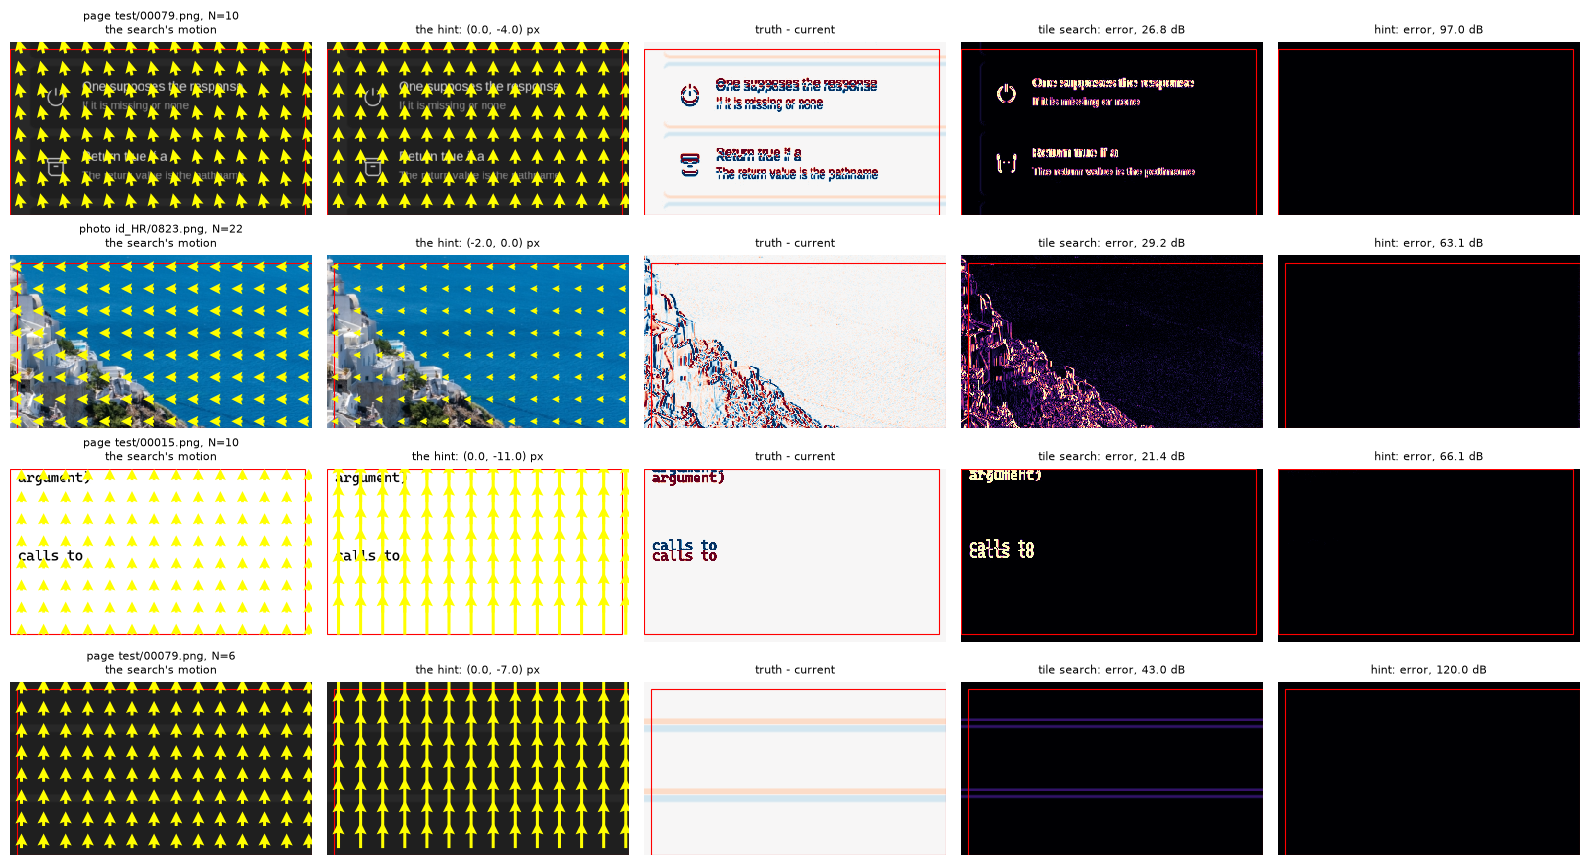

In [8]:
chosen = np.flatnonzero(changed)
gains = []
with torch.no_grad():
    for first in range(0, len(chosen), BATCH_SIZE):
        index = chosen[first:first + BATCH_SIZE]
        previous, current = training.to_tensor(tiles["inputs"][index]).unbind(1)
        target = training.to_tensor(tiles["targets"][index])
        hint = torch.from_numpy(host_hint[index]).to(DEVICE)
        by_search, by_hint = published(previous, current), hinted(previous, current, hint)
        gains += [metrics.wpsnr(by_hint[i:i + 1], target[i:i + 1]) - metrics.wpsnr(by_search[i:i + 1], target[i:i + 1])
                  for i in range(len(index))]
picks = rng.choice(chosen[np.argsort(gains)[::-1][:60]], 4, replace=False)

columns = ["the search's motion", "the hint", "truth - current", "tile search: error", "hint: error"]
fig, axes = plt.subplots(len(picks), len(columns), figsize=(3.2 * len(columns), 2.2 * len(picks)), squeeze=False)
for row, index in enumerate(picks):
    previous, current = training.to_tensor(tiles["inputs"][index:index + 1]).unbind(1)
    target = training.to_tensor(tiles["targets"][index:index + 1])
    hint = torch.from_numpy(host_hint[index:index + 1]).to(DEVICE)
    with torch.no_grad():
        field = search(previous, current).expand(-1, -1, *current.shape[-2:])
        made = {"tile search": published(previous, current), "hint": hinted(previous, current, hint)}
    box = tiles["boxes"][index]
    source = manifest["splits"]["val"]["sources"][tiles["source"][index]]
    ax = axes[row]
    show.motion(ax[0], current, field, f"{source['kind']} {source['file'][-14:]}, N={tiles['frame'][index]}\n"
                f"the search's motion", box, every=24, gain=4)
    show.motion(ax[1], current, -hint[:, :2, None, None].expand(-1, -1, *current.shape[-2:]),
                f"the hint: ({hint[0, 0]:.1f}, {hint[0, 1]:.1f}) px", box, every=24, gain=4)
    show.change(ax[2], current, target, columns[2], box)
    for column, name in ((3, "tile search"), (4, "hint")):
        score = metrics.wpsnr(clips.kept(made[name], box), clips.kept(target, box))
        show.error(ax[column], made[name], target, f"{name}: error, {score:.1f} dB", box)
fig.tight_layout()
plt.show()

### At the stream's own resolution

The grey frames ffmpeg hands a real host are the picture's size, not twice it, and a stream
is often the capture's own size too. Measured on the stream's resolution, whole pixels lose
the half pixel a ×2 scale-down puts a window's motion on; a parabola through the costs either
side of the best offset, on each axis, rounded to half a pixel, gets it back
(`hints.measure(subpixel=True)`). And starting an eighth of the way down with ±2, instead of a
quarter with ±4, reaches as far for half the work - the search desktop-streamer's `hint.js`
runs (`STREAM_HOST`).

In [9]:
"""The host's search on grey frames at the stream's resolution, as desktop-streamer's host has them."""

STREAM_HOST = {"start": 3, "radius": 2, "stop": 0, "sample": 2, "subpixel": True}   # what hint.js runs
STREAM_VARIANTS = {"stream res, whole px": {"start": 2, "radius": 4, "stop": 0, "sample": 2},
                   "stream res, parabola, ±4 from 1/4": {"start": 2, "radius": 4, "stop": 0, "sample": 2, "subpixel": True},
                   "stream res, parabola, ±2 from 1/8 (hint.js)": STREAM_HOST}
found = {name: [] for name in STREAM_VARIANTS}
with torch.no_grad():
    for first in range(0, len(stream_luma), BATCH_SIZE):
        luma = torch.from_numpy(stream_luma[first:first + BATCH_SIZE]).to(DEVICE)
        for name, settings in STREAM_VARIANTS.items():
            levels = settings["start"]
            found[name].append(hints.measure(hints.pyramid(luma[:, :1], levels), hints.pyramid(luma[:, 1:], levels),
                                             **settings).cpu())
at_stream = {"tile search (published)": results["tile search (published)"],
             "source res, half px (the host above)": results["hint, host (pyramid), half px"]}
for name, parts in found.items():
    motion = torch.cat(parts).numpy()
    at_stream[name] = clips.evaluate(hinted, *frames, side=np.concatenate([motion, np.ones((len(motion), 1), np.float32)], 1))
print(f"{'wPSNR (dB), changed':<46}{'all':>8}" + "".join(f"{kind:>10}" for kind in KINDS))
for name, scores in at_stream.items():
    print(f"{name:<46}{scores['changed']['wpsnr']:8.2f}" + "".join(f"{scores[f'{kind}, changed']['wpsnr']:10.2f}" for kind in KINDS))


wPSNR (dB), changed                                all      page   desktop     photo     video   pointer
tile search (published)                          32.84     32.43     28.64     33.48     37.26     29.26
source res, half px (the host above)             38.83     41.91     28.94     38.02     37.85     36.35
stream res, whole px                             37.28     40.44     28.86     35.58     37.51     35.09
stream res, parabola, ±4 from 1/4                38.68     41.64     28.98     37.93     37.89     36.28
stream res, parabola, ±2 from 1/8 (hint.js)      38.58     41.40     29.00     37.95     37.89     36.20


## 7. Export

`models.Hinted` around the published search, as one graph - into `checkpoints/export/`, since no
host can send the hint (see the top): `previous`, `current` and
`hint`, each with `N` symbolic and the frames' `H` and `W` too. `hint` is `[N, 3]` float32,
one row per tile in the client's tile order: the motion (x, y) of that tile from N to N+1
in stream pixels, and 1 if the host's hint arrived (0: the tile takes the search's guess).
Fed a column of zeros it is the published graph; it runs both every time, so it costs the
search's 2.3 ms a 1080p frame and a few elementwise operators more.

In [9]:
filename = f"extrapolate2x_hinted_tilesearch_r{RADIUS}_s{STRIDE}.onnx"
module = hinted.cpu().eval()
EXPORT_DIR = training.CHECKPOINT_DIR / "export"     # not dist/: no host can send the hint
info = webexport.export(module, filename, webexport.TILE_INPUT, models_dir=EXPORT_DIR, label=f"tile search ±{SCALE * RADIUS} px, stride {STRIDE}, "
                        "gated, with the host's hint", dynamic=True, extra={"hint": 3})
for n, h, w in ((36, *webexport.TILE_INPUT), (4, *webexport.TILE_INPUT), (1, 32, 64)):
    pictures = np.random.rand(2, n, 3, h, w).astype(np.float32)
    hint = np.concatenate([np.random.uniform(-12, 12, (n, 2)), np.random.rand(n, 1) > 0.5], 1).astype(np.float32)
    webexport.check_graph(info["path"], module, *pictures, hint=hint)
ms = webexport.time_graph(info["path"], webexport.TILE_INPUT, extra={"hint": 3})
webexport.annotate(info, cpu_ms=round(ms, 2), received_every=STEP,
                   hint="per tile: motion x, y from N to N+1 in stream pixels, and 1 if it arrived")
print(webexport.summary_line(info, ms))
print("checked against torch at 36 and 4 tiles of 328x188 and one of 64x32, half the hints missing")
hinted.to(DEVICE)

extrapolate2x_hinted_tilesearch_r4_s2.onnx             37.5 KB    1.78 ms   Absx1, Addx5, Castx5, Concatx4, Constantx50, ConstantOfShapex1, Convx4, Equalx1, Expandx1, Gatherx4, GreaterOrEqualx1, GridSamplex1, MatMulx1, Mulx10, Negx1, Rangex2, Reciprocalx2, ReduceMeanx1, Reshapex3, Shapex3, Slicex3, Softmaxx1, Subx4, Unsqueezex12, Wherex1   OUTSIDE BUDGET: Abs, Cast, ConstantOfShape, Equal, Expand, Gather, GreaterOrEqual, GridSample, MatMul, Mul, Neg, Range, Reciprocal, ReduceMean, Reshape, Shape, Slice, Softmax, Sub, Unsqueeze, Where
checked against torch at 36 and 4 tiles of 328x188 and one of 64x32, half the hints missing


Hinted(
  (search): TileSearch(
    (luma): Conv2d(3, 1, kernel_size=(2, 2), stride=(2, 2), bias=False)
    (moved): Conv2d(1, 81, kernel_size=(9, 9), stride=(2, 2), bias=False)
    (centre): Conv2d(1, 1, kernel_size=(9, 9), stride=(2, 2), bias=False)
  )
)

## What it says

- **The hint is worth more than everything the client can do.** Measured by the host's cheap
  search, it scores **38.80 dB on the changed tiles against the search's 32.85 (+5.95)** and
  +2.73 dB over every tile - three times notebook 4's ceiling for a picker on the client. It
  knows when a scroll stops: pages 41.88 against 32.46, around the pointer 36.44 against
  29.44, photos 38.01 against 33.49. On the wheel-scrolled clip it averages 49.2 dB a frame,
  where the search averages 38.8 and repeat 41.5.
- **Half a stream pixel matters.** The same search stopped at whole stream pixels scores 37.32,
  1.5 dB less: the host should measure at its own resolution, where a window moves by whole
  pixels, not at the stream's.
- **The host can afford it.** From an eighth of the source with ±1 refinements it finds the
  exhaustive search's motion on 94% of the changed tiles and scores 0.08 dB under it, for
  0.74 million absolute differences a tile - 0.8 billion a second for a 1080p stream. That
  wants SIMD or the GPU, not plain JavaScript.
- **It costs nothing to send.** Two bytes a tile: 17 kbit/s at 1080p, against a stream of
  megabits.
- **One motion per tile still cannot follow a desktop.** The tile hint gains 0.3 dB on
  desktops; a hint per 32 px block gains 5.1 there (33.72) and 3.5 on video - but loses 2.4
  on pages to false matches and whole pixels, and costs ten times the bits. A block hint at
  half pixels, sent only where a block leaves its tile's motion, is the next step for desktops.
- **A late hint costs only its own tile.** With a quarter of them late, the changed tiles are
  still at 37.52, +4.7 over the search; with none, the graph is the published search.

`checkpoints/export/extrapolate2x_hinted_tilesearch_r4_s2.onnx` is the graph a client with
hints would run: the published one plus a `hint` input. It is not published: a real host
captures at the rate it streams, so the frame the hint is measured on does not exist there.
